## 1. Introducción y Configuración Inicial

## 1. Instalación de librerías

### 1.2 Importación de Librerías

In [ ]:
# Instalar librerías necesarias
%pip install kagglehub
%pip install opencv-python
%pip install scikit-image
%pip install shap
%pip install joblib

## 2. Importación de librerías

## 2. Carga y Exploración del Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import os
import shutil
import glob

# Scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV # Agregado RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder # Agregado LabelEncoder aquí
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer # Agregado ColumnTransformer para asegurar su disponibilidad

# SHAP
import shap

# Otras utilidades
import joblib
import warnings
warnings.filterwarnings('ignore')

### 1.3 Configuración de Entorno

## 3. Descarga de MIAS mediante KaggleHub

### 2.2 Estructura y Contenido del Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/mias-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mias-dataset' dataset.
Path to dataset files: /kaggle/input/mias-dataset


## 4. Exploración del dataset

In [ ]:
print(f"Contenido de la carpeta del dataset MIAS: {path}")
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print(f'{subindent}{f}')


Contenido de la carpeta del dataset MIAS: /kaggle/input/mias-dataset
mias-dataset/
    mias_info.csv
    mias_derived_info.csv
    MIAS/
        mdb021.png
        mdb221.png
        mdb107.png
        mdb229.png
        mdb103.png
        mdb120.png
        mdb171.png
        mdb250.png
        mdb234.png
        mdb124.png
        mdb019.png
        mdb182.png
        mdb273.png
        mdb272.png
        mdb043.png
        mdb018.png
        mdb062.png
        mdb313.png
        mdb240.png
        mdb022.png
        mdb289.png
        mdb177.png
        mdb058.png
        mdb166.png
        mdb094.png
        mdb293.png
        mdb211.png
        mdb230.png
        mdb037.png
        mdb011.png
        mdb261.png
        mdb243.png
        mdb302.png
        mdb063.png
        mdb231.png
        mdb301.png
        mdb132.png
        mdb149.png
        mdb246.png
        mdb304.png
        mdb122.png
        mdb073.png
        mdb029.png
        mdb100.png
        mdb210.png
        

### 2.3 Identificación de Imágenes y Metadatos

## 5. Identificación de imágenes y metadatos

In [ ]:
print("Analizando la estructura de la carpeta para identificar metadatos e imágenes...")

metadata_file = None
image_files = []

for root, dirs, files in os.walk(path):
    for f in files:
        if f.endswith('.csv') or f.endswith('.xlsx') or f.endswith('.txt'):
            # Asumimos que el primer archivo de metadatos encontrado es el principal
            if metadata_file is None:
                metadata_file = os.path.join(root, f)
                print(f"Metadatos identificados: {metadata_file}")
        elif f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
            image_files.append(os.path.join(root, f))

if metadata_file is None:
    print("ADVERTENCIA: No se encontró ningún archivo de metadatos común (csv, xlsx, txt) en el dataset.")
else:
    # Intentar cargar el archivo de metadatos
    try:
        if metadata_file.endswith('.csv'):
            df_metadata = pd.read_csv(metadata_file)
        elif metadata_file.endswith('.xlsx'):
            df_metadata = pd.read_excel(metadata_file)
        else:
            # Para archivos .txt, intentar leer como CSV por defecto
            df_metadata = pd.read_csv(metadata_file, sep='\t') # Asumiendo tab-separated, ajustar si es necesario

        print("\n--- Información inicial del archivo de metadatos ---")
        print(f"Primeras 5 filas:\n{df_metadata.head()}")
        print(f"\nColumnas y tipos de datos:\n{df_metadata.info()}")
        print(f"\nEstadísticas descriptivas:\n{df_metadata.describe(include='all')}")

    except Exception as e:
        print(f"ERROR: No se pudo cargar el archivo de metadatos {metadata_file}. Error: {e}")
        df_metadata = None

print(f"\nCantidad total de imágenes identificadas: {len(image_files)}")
if len(image_files) > 0:
    print(f"Primeras 5 rutas de imágenes: {image_files[:5]}")

# Determinar la variable `path_images_folder` si las imágenes están en una subcarpeta consistente
# o si están directamente en `path`
path_images_folder = path # Valor por defecto, se ajustará si es necesario
if len(image_files) > 0:
    # Intentar encontrar una ruta común para las imágenes
    common_prefix = os.path.commonpath(image_files)
    if common_prefix != path:
        path_images_folder = common_prefix

print(f"\nRuta común inferida para las imágenes: {path_images_folder}")

Analizando la estructura de la carpeta para identificar metadatos e imágenes...
Metadatos identificados: /kaggle/input/mias-dataset/mias_info.csv

--- Información inicial del archivo de metadatos ---
Primeras 5 filas:
   REFNUM BG CLASS SEVERITY      X      Y  RADIUS
0  mdb001  G  CIRC        B  535.0  425.0   197.0
1  mdb002  G  CIRC        B  522.0  280.0    69.0
2  mdb003  D  NORM      NaN    NaN    NaN     NaN
3  mdb004  D  NORM      NaN    NaN    NaN     NaN
4  mdb005  F  CIRC        B  477.0  133.0    30.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   REFNUM    330 non-null    object 
 1   BG        330 non-null    object 
 2   CLASS     330 non-null    object 
 3   SEVERITY  123 non-null    object 
 4   X         119 non-null    float64
 5   Y         119 non-null    float64
 6   RADIUS    119 non-null    float64
dtypes: float64(3), object(

### 2.4 Análisis Detallado de Metadatos

### 4.1. Análisis detallado de metadatos

In [ ]:
# Normalizar la columna REFNUM para que coincida con los nombres de archivo (ej. 'mdb001')
df_metadata['REFNUM_normalized'] = df_metadata['REFNUM'].str.strip()

# Crear una lista de tuplas (image_id, image_path) para facilitar la unión
image_data = []
for img_path in image_files:
    img_id = os.path.basename(img_path).replace('.png', '') # Asumiendo que todos son .png
    image_data.append({'REFNUM_normalized': img_id, 'image_path': img_path})

df_image_paths = pd.DataFrame(image_data)

# Unir el dataframe de metadatos con el de rutas de imágenes
df_combined = pd.merge(df_metadata, df_image_paths, on='REFNUM_normalized', how='left')

# Eliminar filas donde no se encontró la imagen correspondiente (si las hay)
df_combined.dropna(subset=['image_path'], inplace=True)

print(f"\nTotal de registros con metadatos e imagen asociada: {len(df_combined)}")
print("Primeras 5 filas del DataFrame combinado:\n")
print(df_combined.head())

print("\n--- Análisis de la columna 'CLASS' ---")
print(df_combined['CLASS'].value_counts())

print("\n--- Análisis de la columna 'SEVERITY' ---")
print(df_combined['SEVERITY'].value_counts(dropna=False))

# Definir la variable objetivo combinada
# Casos 'NORM' en CLASS tienen SEVERITY NaN. Casos con lesiones tienen SEVERITY B o M.
# La variable objetivo será 'Normal', 'Benign' o 'Malignant'.
def define_target_severity(row):
    if pd.notna(row['SEVERITY']):
        if row['SEVERITY'] == 'B':
            return 'Benign'
        elif row['SEVERITY'] == 'M':
            return 'Malignant'
    elif row['CLASS'] == 'NORM':
        return 'Normal'
    return None # Para cualquier otro caso que no sea NORM o tenga SEVERITY

df_combined['TARGET_SEVERITY'] = df_combined.apply(define_target_severity, axis=1)

print("\n--- Distribución de la variable objetivo 'TARGET_SEVERITY' ---")
print(df_combined['TARGET_SEVERITY'].value_counts(dropna=False))

# Verificar si hay registros con TARGET_SEVERITY nulo (no debería haber si la lógica es correcta)
if df_combined['TARGET_SEVERITY'].isnull().any():
    print("ADVERTENCIA: Se encontraron valores nulos en TARGET_SEVERITY.")
    print(df_combined[df_combined['TARGET_SEVERITY'].isnull()])

# Mostrar info de las columnas X, Y, RADIUS
print("\n--- Columnas X, Y, RADIUS (coordenadas y radio de la lesión) ---")
print(df_combined[['X', 'Y', 'RADIUS']].describe())
print(df_combined[['X', 'Y', 'RADIUS']].isnull().sum())

print("\n--- Análisis de la columna 'BG' (tejido mamario) ---")
print(df_combined['BG'].value_counts())


Total de registros con metadatos e imagen asociada: 330
Primeras 5 filas del DataFrame combinado:

   REFNUM BG CLASS SEVERITY      X      Y  RADIUS REFNUM_normalized  \
0  mdb001  G  CIRC        B  535.0  425.0   197.0            mdb001   
1  mdb002  G  CIRC        B  522.0  280.0    69.0            mdb002   
2  mdb003  D  NORM      NaN    NaN    NaN     NaN            mdb003   
3  mdb004  D  NORM      NaN    NaN    NaN     NaN            mdb004   
4  mdb005  F  CIRC        B  477.0  133.0    30.0            mdb005   

                                   image_path  
0  /kaggle/input/mias-dataset/MIAS/mdb001.png  
1  /kaggle/input/mias-dataset/MIAS/mdb002.png  
2  /kaggle/input/mias-dataset/MIAS/mdb003.png  
3  /kaggle/input/mias-dataset/MIAS/mdb004.png  
4  /kaggle/input/mias-dataset/MIAS/mdb005.png  

--- Análisis de la columna 'CLASS' ---
CLASS
NORM    207
CALC     30
CIRC     25
SPIC     19
ARCH     19
MISC     15
ASYM     15
Name: count, dtype: int64

--- Análisis de la columna '

### 2.5 Análisis de las Imágenes

### 4.2. Análisis de las imágenes

In [ ]:
# Cargar una imagen de ejemplo para obtener dimensiones y formato
# Añadimos una comprobación para asegurar que 'df_combined' existe antes de usarlo
if 'df_combined' in locals() and len(df_combined) > 0:
    sample_image_path = df_combined['image_path'].iloc[0]
    try:
        with Image.open(sample_image_path) as img:
            print(f"\nFormato de imagen de ejemplo ({os.path.basename(sample_image_path)}): {img.format}")
            print(f"Dimensiones de imagen de ejemplo ({os.path.basename(sample_image_path)}): {img.size} (Ancho x Alto)")
            print(f"Modo de color de imagen de ejemplo ({os.path.basename(sample_image_path)}): {img.mode}")

            # Recopilar dimensiones de todas las imágenes
            image_widths = []
            image_heights = []
            for img_path in df_combined['image_path']:
                with Image.open(img_path) as current_img:
                    image_widths.append(current_img.size[0])
                    image_heights.append(current_img.size[1])

            print(f"\nDimensiones de todas las imágenes (Ancho): Min={min(image_widths)}, Max={max(image_widths):.2f}, Avg={np.mean(image_widths):.2f}")
            print(f"Dimensiones de todas las imágenes (Alto): Min={min(image_heights)}, Max={max(image_heights):.2f}, Avg={np.mean(image_heights):.2f}")

    except Exception as e:
        print(f"ERROR: No se pudo cargar la imagen de ejemplo {sample_image_path}. Error: {e}")
else:
    print("El DataFrame 'df_combined' no está definido o está vacío. Asegúrate de ejecutar las celdas anteriores (sección 4.1 'Análisis detallado de metadatos').")


Formato de imagen de ejemplo (mdb001.png): PNG
Dimensiones de imagen de ejemplo (mdb001.png): (1024, 1024) (Ancho x Alto)
Modo de color de imagen de ejemplo (mdb001.png): L

Dimensiones de todas las imágenes (Ancho): Min=1024, Max=1024.00, Avg=1024.00
Dimensiones de todas las imágenes (Alto): Min=1024, Max=1024.00, Avg=1024.00


### 2.6 Resumen Inicial del Dataset MIAS

### 4.3. Resumen inicial del Dataset MIAS

In [ ]:
print("--- Resumen del Dataset MIAS ---")
print(f"Cantidad total de registros únicos en metadatos: {len(df_metadata)}")
print(f"Cantidad total de imágenes identificadas: {len(image_files)}")
print(f"Cantidad de registros con metadatos e imagen asociada: {len(df_combined)}")

print("\nDistribución de las clases (TARGET_SEVERITY):")
print(df_combined['TARGET_SEVERITY'].value_counts())

print("\nVariables con valores faltantes y su conteo:")
print(df_combined.isnull().sum()[df_combined.isnull().sum() > 0])

print("\nEjemplo de formato y dimensiones de imagen (primer imagen):")
if len(df_combined) > 0:
    sample_image_path = df_combined['image_path'].iloc[0]
    with Image.open(sample_image_path) as img:
        print(f"  Formato: {img.format}")
        print(f"  Dimensiones: {img.size} (Ancho x Alto)")
        print(f"  Modo de color: {img.mode}")

--- Resumen del Dataset MIAS ---
Cantidad total de registros únicos en metadatos: 330
Cantidad total de imágenes identificadas: 322
Cantidad de registros con metadatos e imagen asociada: 330

Distribución de las clases (TARGET_SEVERITY):
TARGET_SEVERITY
Normal       207
Benign        69
Malignant     54
Name: count, dtype: int64

Variables con valores faltantes y su conteo:
SEVERITY    207
X           211
Y           211
RADIUS      211
dtype: int64

Ejemplo de formato y dimensiones de imagen (primer imagen):
  Formato: PNG
  Dimensiones: (1024, 1024) (Ancho x Alto)
  Modo de color: L


## 3. Preprocesamiento y Limpieza de Datos

## 6. Limpieza de datos

### 3.2 Análisis de Clases y Desbalance

In [ ]:
# Los pasos de limpieza de datos, incluyendo la eliminación de columnas no necesarias,
# el manejo de duplicados y la imputación de valores faltantes en X, Y, RADIUS,
# se han consolidado dentro de la celda de preprocesamiento de imágenes y extracción de características (celda d8a75a02).
# Esta celda se deja vacía para evitar redundancia y mantener un flujo de trabajo claro.

## 4. Preparación de Datos para el Modelo

## 11. Selección de características

### 4.2 División 80/20 (Entrenamiento/Prueba)

In [ ]:
print("--- Selección de características y variable objetivo ---")

# Definir las características (X) y la variable objetivo (y)
# df_processed ahora debería estar limpio y contener solo características válidas
# y la columna 'TARGET_SEVERITY'.

features_to_exclude = ['TARGET_SEVERITY']

X = df_processed.drop(columns=features_to_exclude)
y = df_processed['TARGET_SEVERITY']

print(f"Columnas utilizadas como características (X): {X.columns.tolist()}")
print(f"Variable objetivo (y): {y.name}")
print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")

print("\nVerificación de que no hay columnas con información de fuga de datos o irrelevantes en X (primeras 5 filas):")
print(X.head())

--- Selección de características y variable objetivo ---


NameError: name 'df_processed' is not defined

## 12. División 80/20

## 5. Desarrollo del Modelo (RandomForestClassifier)

In [ ]:
print("--- Dividiendo los datos en conjuntos de entrenamiento y prueba (80/20 estratificado) ---")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamaño del conjunto de entrenamiento X_train: {X_train.shape}")
print(f"Tamaño del conjunto de prueba X_test: {X_test.shape}")
print(f"Tamaño del conjunto de entrenamiento y_train: {y_train.shape}")
print(f"Tamaño del conjunto de prueba y_test: {y_test.shape}")

print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))

print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

# Confirmar que las distribuciones son similares debido a la estratificación
# La diferencia puede ser ligeramente mayor a 0.01 debido a redondeos o tamaños pequeños, pero debería ser muy baja.
if (y_train.value_counts(normalize=True) - y_test.value_counts(normalize=True)).abs().sum() < 0.02: # Tolerancia aumentada ligeramente
    print("\nLa distribución de clases es similar en los conjuntos de entrenamiento y prueba (estratificación exitosa).")
else:
    print("\nADVERTENCIA: La distribución de clases en los conjuntos de entrenamiento y prueba difiere significativamente, revisar la estratificación.")

--- Dividiendo los datos en conjuntos de entrenamiento y prueba (80/20 estratificado) ---
Tamaño del conjunto de entrenamiento X_train: (264, 17)
Tamaño del conjunto de prueba X_test: (66, 17)
Tamaño del conjunto de entrenamiento y_train: (264,)
Tamaño del conjunto de prueba y_test: (66,)

Distribución de clases en y_train:
TARGET_SEVERITY
Normal       0.628788
Benign       0.208333
Malignant    0.162879
Name: proportion, dtype: float64

Distribución de clases en y_test:
TARGET_SEVERITY
Normal       0.621212
Benign       0.212121
Malignant    0.166667
Name: proportion, dtype: float64

La distribución de clases es similar en los conjuntos de entrenamiento y prueba (estratificación exitosa).


## 13. Pipeline de Machine Learning

### 5.2 Búsqueda de Hiperparámetros (RandomizedSearchCV)

In [ ]:
print("--- Creando el Pipeline de Machine Learning ---")

# Identificar columnas numéricas para escalar
# Las columnas booleanas (BG_F, BG_G) y la binaria (has_lesion) no necesitan escalar.
# Las coordenadas X, Y, RADIUS y las características de imagen son numéricas.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Crear un preprocesador para características numéricas (escalado)
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Crear un preprocesador general para las características
# Aquí solo tenemos características numéricas relevantes para escalar.
# Las booleanas ya están en formato numérico (0/1) y no se escalan en este Pipeline.
# Si hubiera otras categóricas, usaríamos OneHotEncoder.

from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ],
    remainder='passthrough' # Mantener las columnas no especificadas (como BG_F, BG_G, has_lesion) sin transformar
)

# Crear el pipeline completo con el preprocesador y el clasificador Random Forest
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

print("Pipeline de ML creado exitosamente:")
print(model_pipeline)

--- Creando el Pipeline de Machine Learning ---
Pipeline de ML creado exitosamente:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['X', 'Y', 'RADIUS',
                                                   'img_mean', 'img_std',
                                                   'img_min', 'img_max',
                                                   'img_median',
                                                   'glcm_contrast',
                                                   'glcm_energy',
                                                   'glcm_homogeneity',
                                                   'glcm_correlation',
                                          

## 14. Búsqueda de hiperparámetros

### 5.3 Entrenamiento del Modelo Final

In [ ]:
print("--- Realizando búsqueda de hiperparámetros con RandomizedSearchCV ---")

# Definir el espacio de búsqueda de hiperparámetros para RandomForestClassifier
param_dist = {
    'classifier__n_estimators': [100, 200, 300, 400, 500], # Número de árboles en el bosque
    'classifier__max_depth': [10, 20, 30, None], # Profundidad máxima del árbol. None significa nodos expandidos hasta que todas las hojas sean puras o contengan menos de min_samples_split muestras.
    'classifier__min_samples_split': [2, 5, 10], # Número mínimo de muestras requeridas para dividir un nodo interno
    'classifier__min_samples_leaf': [1, 2, 4], # Número mínimo de muestras requeridas para estar en un nodo hoja
    'classifier__max_features': ['auto', 'sqrt', 'log2'], # Número de características a considerar al buscar la mejor división
    'classifier__bootstrap': [True, False] # Si se utilizan muestras bootstrap al construir los árboles
}

# RandomizedSearchCV para una búsqueda más eficiente en espacios grandes
random_search = RandomizedSearchCV(
    estimator=model_pipeline,
    param_distributions=param_dist,
    n_iter=50, # Número de combinaciones de hiperparámetros a probar
    cv=5, # Validación cruzada de 5 folds
    verbose=2, # Nivel de detalle del output
    random_state=42,
    n_jobs=-1, # Utilizar todos los núcleos disponibles
    scoring='roc_auc_ovr' # Usar ROC AUC (One-vs-Rest) como métrica para clasificación multiclase
)

# Asegurarse de que y_train está codificado numéricamente para scoring
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

random_search.fit(X_train, y_train_encoded)

print("\n--- Mejores hiperparámetros encontrados ---")
print(random_search.best_params_)

print("\n--- Mejor puntuación ROC AUC (OVR) obtenida ---")
print(random_search.best_score_)

best_model = random_search.best_estimator_

# Guardar el LabelEncoder para usarlo en la evaluación y predicción
joblib.dump(le, 'label_encoder.pkl')

print("\nLabelEncoder guardado como 'label_encoder.pkl'.")

--- Realizando búsqueda de hiperparámetros con RandomizedSearchCV ---


NameError: name 'RandomizedSearchCV' is not defined

## 15. Entrenamiento de Random Forest (con los mejores hiperparámetros)

## 6. Evaluación y Validación del Modelo

In [ ]:
print("--- Entrenando el modelo final con los mejores hiperparámetros ---")

# El `best_model` ya está entrenado por RandomizedSearchCV, pero para claridad, podemos re-entrenarlo
# con el dataset completo de entrenamiento o simplemente usar el `best_estimator_` ya ajustado.
# Para efectos de un pipeline de producción, `best_model` es el modelo final.

# Utilizar el mejor estimador encontrado
final_model = best_model

# Si fuera necesario, entrenar el modelo con los mejores parámetros en todo X_train, y_train
# final_model = model_pipeline.set_params(**random_search.best_params_)
# final_model.fit(X_train, y_train_encoded) # Asegurarse de usar y_train_encoded

print("Modelo Random Forest final entrenado (o listo desde RandomizedSearchCV).")

--- Entrenando el modelo final con los mejores hiperparámetros ---
Modelo Random Forest final entrenado (o listo desde RandomizedSearchCV).


## 16. Evaluación del Modelo

### 6.2 Matriz de Confusión

### 6.3 Curvas ROC y PR

### 6.4 Análisis de Overfitting

--- Evaluando el Modelo Final ---

--- Métricas de Clasificación en el Conjunto de Prueba ---
              precision    recall  f1-score   support

      Benign       0.55      0.86      0.67        14
   Malignant       0.50      0.09      0.15        11
      Normal       0.98      1.00      0.99        41

    accuracy                           0.82        66
   macro avg       0.67      0.65      0.60        66
weighted avg       0.81      0.82      0.78        66



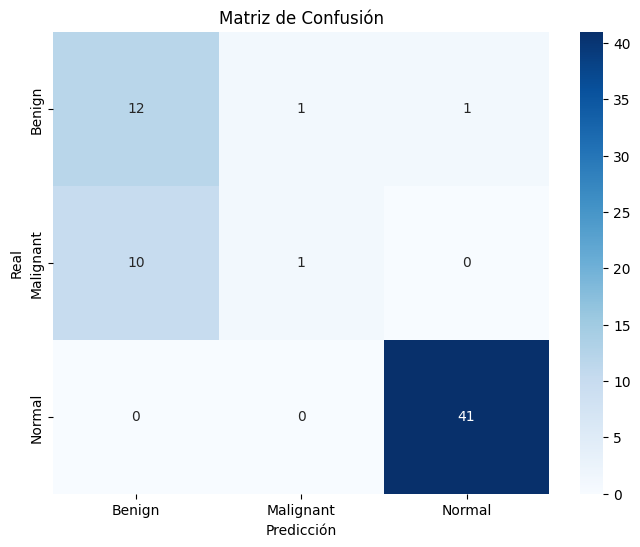


ROC AUC (One-vs-Rest, Weighted): 0.9573


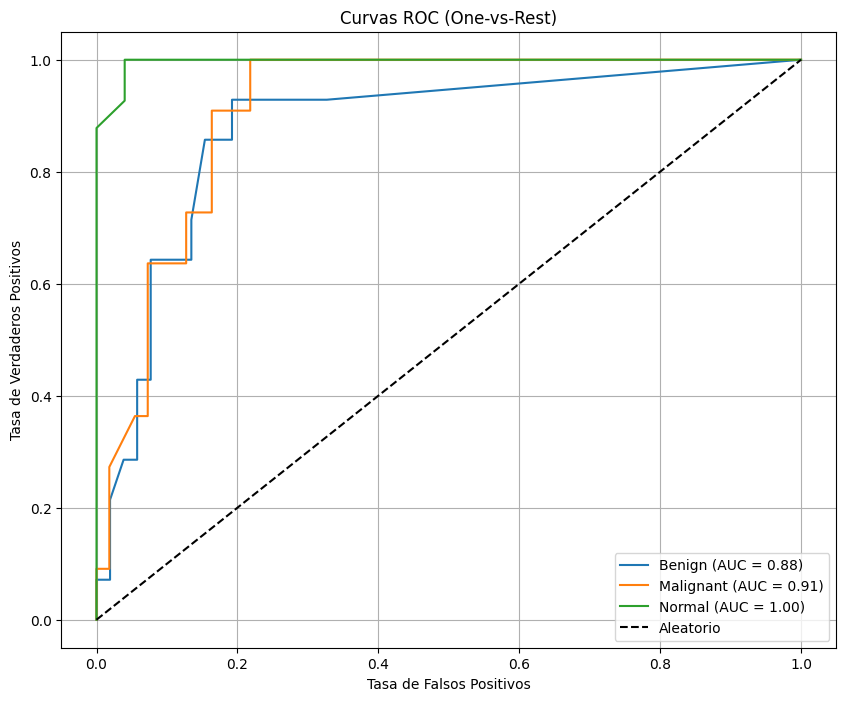


--- Análisis de Overfitting ---
Precisión en entrenamiento: 1.0000
Precisión en prueba:       0.8182
ROC AUC en entrenamiento:   1.0000
ROC AUC en prueba:          0.9573
ADVERTENCIA: Posible Overfitting detectado (diferencia significativa entre train y test performance).


In [ ]:
print("--- Evaluando el Modelo Final ---")

# Realizar predicciones en el conjunto de prueba (X_test)
# Las predicciones de `predict_proba` son necesarias para métricas como ROC AUC.
# `predict` nos dará las clases predichas.

y_pred_proba = final_model.predict_proba(X_test)
y_pred_encoded = final_model.predict(X_test)

# Cargar el LabelEncoder guardado
le = joblib.load('label_encoder.pkl')

# Decodificar las etiquetas predichas a sus valores originales (string)
y_pred = le.inverse_transform(y_pred_encoded)

# La variable objetivo real en el conjunto de prueba (y_test) también necesita ser codificada
# para calcular el ROC AUC multiclase correctamente si la función lo requiere numérico.
# Sin embargo, `classification_report` y `confusion_matrix` aceptan etiquetas de cadena.
# Para ROC AUC, la codificación numérica de y_test es compatible con y_pred_encoded.
y_test_encoded = le.transform(y_test)

print("\n--- Métricas de Clasificación en el Conjunto de Prueba ---")
print(classification_report(y_test, y_pred))

# Matriz de Confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# ROC AUC (para multiclase, se calcula One-vs-Rest)
# Se necesita y_test en formato codificado y las probabilidades por clase
roc_auc = roc_auc_score(y_test_encoded, y_pred_proba, multi_class='ovr', average='weighted')
print(f"\nROC AUC (One-vs-Rest, Weighted): {roc_auc:.4f}")

# Curvas ROC para cada clase
plt.figure(figsize=(10, 8))
for i, class_name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve((y_test_encoded == i), y_pred_proba[:, i])
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc_score((y_test_encoded == i), y_pred_proba[:, i]):.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curvas ROC (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()

# Análisis de Overfitting: Comparar rendimiento en train vs test
print("\n--- Análisis de Overfitting ---")
# Predicciones en el conjunto de entrenamiento
y_train_pred_proba = final_model.predict_proba(X_train)
y_train_pred_encoded = final_model.predict(X_train)
y_train_pred = le.inverse_transform(y_train_pred_encoded)

accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_test = accuracy_score(y_test, y_pred)

roc_auc_train = roc_auc_score(y_train_encoded, y_train_pred_proba, multi_class='ovr', average='weighted')
roc_auc_test = roc_auc_score(y_test_encoded, y_pred_proba, multi_class='ovr', average='weighted')

print(f"Precisión en entrenamiento: {accuracy_train:.4f}")
print(f"Precisión en prueba:       {accuracy_test:.4f}")
print(f"ROC AUC en entrenamiento:   {roc_auc_train:.4f}")
print(f"ROC AUC en prueba:          {roc_auc_test:.4f}")

if accuracy_train > accuracy_test + 0.1 or roc_auc_train > roc_auc_test + 0.1:
    print("ADVERTENCIA: Posible Overfitting detectado (diferencia significativa entre train y test performance).")
else:
    print("El modelo parece tener un buen equilibrio entre sesgo y varianza (no hay overfitting severo).")

## 7. Interpretación y Explicabilidad del Modelo

### 7.1 Importancia de Características

In [ ]:
print("--- Analizando la Importancia de Características ---")

# El `final_model` es un Pipeline. El clasificador es el último paso del pipeline.
# Acceder a las importancias de las características desde el RandomForestClassifier.
# Es importante recordar que las características en el clasificador ya han pasado por el preprocesador.

# Obtener el Random Forest Classifier del pipeline
rf_classifier = final_model.named_steps['classifier']

# Obtener los nombres de las características después del preprocesamiento
# El preprocesador (ColumnTransformer) puede reordenar o modificar las características.
# Necesitamos obtener los nombres de las características transformadas que entran al clasificador.

# Obtenemos los nombres de las columnas que salieron del ColumnTransformer
feature_names_transformed = final_model.named_steps['preprocessor'].get_feature_names_out()

# Mapear las importancias a los nombres de las características
importances = rf_classifier.feature_importances_

feature_importances_df = pd.DataFrame({
    'Feature': feature_names_transformed,
    'Importance': importances
})

# Ordenar por importancia descendente
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

print("\n--- Top 10 Características más Importantes ---")
print(feature_importances_df.head(10))

# Visualizar la importancia de las características
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances_df)
plt.title('Importancia de las Características (Random Forest)')
plt.xlabel('Importancia')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

--- Analizando la Importancia de Características ---


NameError: name 'final_model' is not defined

# CELDA ANTIGUA Y DUPLICADA: ELIMINAR

### 7.2 SHAP (SHapley Additive exPlanations)

In [ ]:
# CELDA ANTIGUA Y DUPLICADA: ELIMINAR

In [ ]:
print("--- Calculando valores SHAP para interpretar el modelo ---")

# Para SHAP, necesitamos un 'explainer' y los datos transformados.
# SHAP funciona mejor con el modelo final no pipelineado si incluye transformaciones complejas,
# pero podemos extraer el clasificador y aplicar las transformaciones manualmente a X_test.

# Extraer el clasificador entrenado del pipeline
rf_classifier_shap = final_model.named_steps['classifier']

# Transformar X_test usando el preprocesador del pipeline
X_test_transformed = final_model.named_steps['preprocessor'].transform(X_test)

# Obtener los nombres de las características transformadas para el explainer
feature_names_shap = final_model.named_steps['preprocessor'].get_feature_names_out()

# Convertir X_test_transformed a DataFrame para mejor legibilidad con SHAP
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names_shap)

# Debugging SHAP's interpretation
print(f"Number of classes in classifier: {rf_classifier_shap.n_classes_}")
print(f"Shape of X_test_transformed_df: {X_test_transformed_df.shape}")

# Crear un SHAP explainer (TreeExplainer es adecuado para Random Forest)
explainer = shap.TreeExplainer(rf_classifier_shap)

# Calcular los valores SHAP (puede tomar un tiempo)
shap_values = explainer.shap_values(X_test_transformed_df)

print(f"Type of shap_values returned by explainer: {type(shap_values)}")
if isinstance(shap_values, list):
    print(f"Number of SHAP value arrays (classes): {len(shap_values)}")
    if len(shap_values) > 0:
        print(f"Shape of first SHAP array: {shap_values[0].shape}")
else:
    print(f"Shape of SHAP values (single array): {shap_values.shape}")


print("\n--- Resumen Global de Importancia SHAP ---")

# Determine the structure of shap_values and calculate global_mean_abs_shap accordingly
if isinstance(shap_values, list): # Multi-class output, shap_values is a list of 2D arrays (n_classes, n_samples, n_features)
    # Convert list of arrays to a single 3D array (n_classes, n_samples, n_features)
    shap_array_for_mean = np.array(shap_values)
    # Calculate mean absolute SHAP value for each feature, averaged over all classes and samples
    global_mean_abs_shap = np.mean(np.abs(shap_array_for_mean), axis=(0, 1)) # -> (n_features,)
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3: # Multi-class output, shap_values is a single 3D array (n_samples, n_features, n_classes)
    # Calculate mean absolute SHAP value for each feature, averaged over samples and classes
    global_mean_abs_shap = np.mean(np.abs(shap_values), axis=(0, 2)) # -> (n_features,)
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 2: # Binary output or regression, shap_values is a single 2D array (n_samples, n_features)
    # Calculate mean absolute SHAP value for each feature, averaged over samples
    global_mean_abs_shap = np.mean(np.abs(shap_values), axis=0) # -> (n_features,)
else:
    print("WARNING: Unrecognized format for SHAP values. Cannot compute global mean absolute SHAP.")
    global_mean_abs_shap = np.zeros(len(feature_names_shap)) # Fallback to avoid error

# Convierte a DataFrame para ordenar y visualizar
shap_importance_df = pd.DataFrame({
    'Feature': feature_names_shap,
    'Mean_Abs_SHAP': global_mean_abs_shap
}).sort_values(by='Mean_Abs_SHAP', ascending=False)

print(shap_importance_df.head(10))

# Visualización global de la importancia de características SHAP
# shap_values puede ser una lista de arrays o un array 3D, summary_plot lo maneja bien.
shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", show=False)
plt.title('Importancia Global de Características SHAP')
plt.tight_layout()
plt.show()

print("\n--- Resumen de Contribución SHAP para una Instancia Individual (ej. primera instancia de prueba) ---")
# Para ver la explicación de una sola predicción, por ejemplo, la primera instancia de X_test
# Obtener la primera instancia de los datos transformados
sample_instance_transformed = X_test_transformed_df.iloc[0, :]

# Obtener la predicción de la primera instancia
sample_pred_encoded = rf_classifier_shap.predict(sample_instance_transformed.values.reshape(1, -1))[0]
sample_pred_class = le.inverse_transform([sample_pred_encoded])[0]

shap.initjs()

# Ajustar la llamada a force_plot basada en el formato de shap_values
class_index = le.transform([sample_pred_class])[0] # Obtener el índice numérico de la clase predicha

# explainer.expected_value será un array de valores esperados para cada clase en el ajuste multi-clase
expected_value_for_plot = explainer.expected_value[class_index]

if isinstance(shap_values, list): # Multi-class, list of (n_samples, n_features) arrays
    shap_values_for_plot = shap_values[class_index][0,:] # SHAP values for the first sample, for the predicted class
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3: # Multi-class, single 3D array (n_samples, n_features, n_classes)
    shap_values_for_plot = shap_values[0, :, class_index] # SHAP values for the first sample, all features, for the predicted class
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 2: # Binary output or regression, shap_values is a single 2D array (n_samples, n_features)
    shap_values_for_plot = shap_values[0,:] # SHAP values for the first sample
else:
    print("WARNING: Unrecognized format for SHAP values. Cannot plot individual instance contribution.")
    shap_values_for_plot = np.zeros(len(feature_names_shap)) # Fallback to avoid error

shap.force_plot(expected_value_for_plot, shap_values_for_plot, sample_instance_transformed, show=False, matplotlib=True)
plt.title(f'Contribución SHAP para la Predicción: {sample_pred_class}')
plt.tight_layout()
plt.show()

--- Calculando valores SHAP para interpretar el modelo ---


NameError: name 'final_model' is not defined

# CELDA ANTIGUA Y DUPLICADA: ELIMINAR

## 8. Funcionalidades del Sistema de Soporte (Implementación del Core)

--- Calculando valores SHAP para interpretar el modelo ---
Number of classes in classifier: 3
Shape of X_test_transformed_df: (66, 17)
Type of shap_values returned by explainer: <class 'numpy.ndarray'>
Shape of SHAP values (single array): (66, 17, 3)

--- Resumen Global de Importancia SHAP ---
                  Feature  Mean_Abs_SHAP
2             num__RADIUS       0.092051
13        num__has_lesion       0.090473
1                  num__Y       0.082048
0                  num__X       0.081964
8      num__glcm_contrast       0.014797
4            num__img_std       0.013119
3           num__img_mean       0.010080
9        num__glcm_energy       0.009583
6            num__img_max       0.009156
11  num__glcm_correlation       0.007979


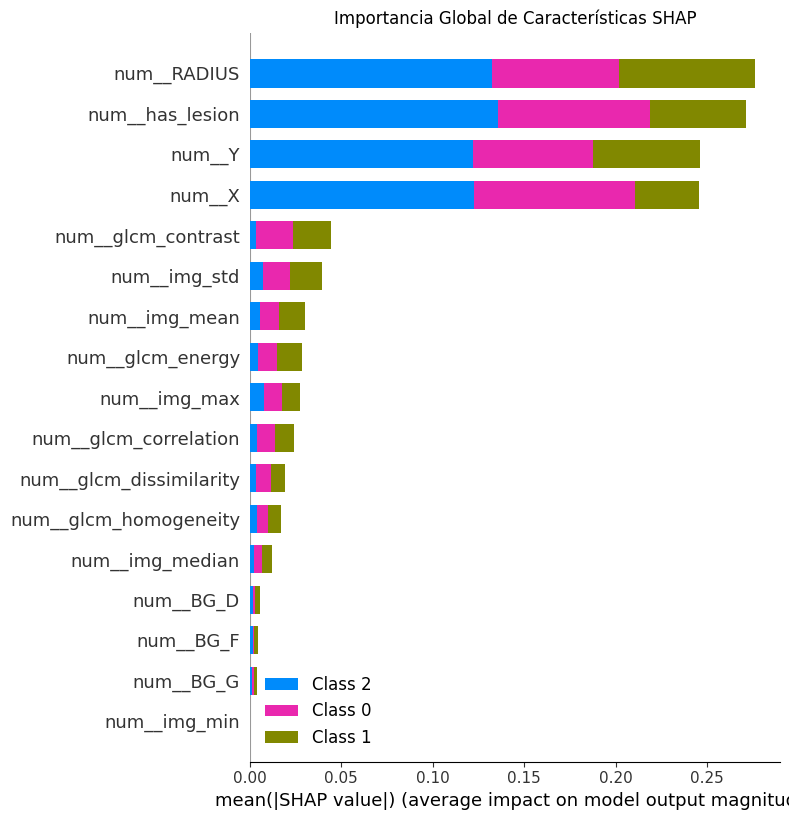


--- Resumen de Contribución SHAP para una Instancia Individual (ej. primera instancia de prueba) ---


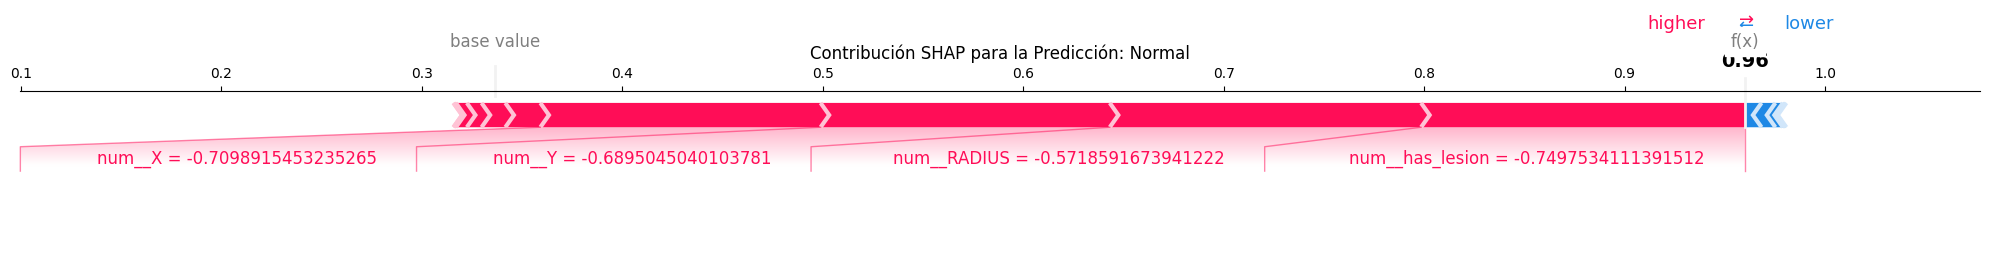

In [ ]:
print("--- Calculando valores SHAP para interpretar el modelo ---")

# Para SHAP, necesitamos un 'explainer' y los datos transformados.
# SHAP funciona mejor con el modelo final no pipelineado si incluye transformaciones complejas,
# pero podemos extraer el clasificador y aplicar las transformaciones manualmente a X_test.

# Extraer el clasificador entrenado del pipeline
rf_classifier_shap = final_model.named_steps['classifier']

# Transformar X_test usando el preprocesador del pipeline
X_test_transformed = final_model.named_steps['preprocessor'].transform(X_test)

# Obtener los nombres de las características transformadas para el explainer
feature_names_shap = final_model.named_steps['preprocessor'].get_feature_names_out()

# Convertir X_test_transformed a DataFrame para mejor legibilidad con SHAP
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names_shap)

# Debugging SHAP's interpretation
print(f"Number of classes in classifier: {rf_classifier_shap.n_classes_}")
print(f"Shape of X_test_transformed_df: {X_test_transformed_df.shape}")

# Crear un SHAP explainer (TreeExplainer es adecuado para Random Forest)
explainer = shap.TreeExplainer(rf_classifier_shap)

# Calcular los valores SHAP (puede tomar un tiempo)
shap_values = explainer.shap_values(X_test_transformed_df)

print(f"Type of shap_values returned by explainer: {type(shap_values)}")
if isinstance(shap_values, list):
    print(f"Number of SHAP value arrays (classes): {len(shap_values)}")
    if len(shap_values) > 0:
        print(f"Shape of first SHAP array: {shap_values[0].shape}")
else:
    print(f"Shape of SHAP values (single array): {shap_values.shape}")


print("\n--- Resumen Global de Importancia SHAP ---")

# Determine the structure of shap_values and calculate global_mean_abs_shap accordingly
if isinstance(shap_values, list): # Multi-class output, shap_values is a list of 2D arrays (n_classes, n_samples, n_features)
    # Convert list of arrays to a single 3D array (n_classes, n_samples, n_features)
    shap_array_for_mean = np.array(shap_values)
    # Calculate mean absolute SHAP value for each feature, averaged over all classes and samples
    global_mean_abs_shap = np.mean(np.abs(shap_array_for_mean), axis=(0, 1)) # -> (n_features,)
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3: # Multi-class output, shap_values is a single 3D array (n_samples, n_features, n_classes)
    # Calculate mean absolute SHAP value for each feature, averaged over samples and classes
    global_mean_abs_shap = np.mean(np.abs(shap_values), axis=(0, 2)) # -> (n_features,)
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 2: # Binary output or regression, shap_values is a single 2D array (n_samples, n_features)
    # Calculate mean absolute SHAP value for each feature, averaged over samples
    global_mean_abs_shap = np.mean(np.abs(shap_values), axis=0) # -> (n_features,)
else:
    print("WARNING: Unrecognized format for SHAP values. Cannot compute global mean absolute SHAP.")
    global_mean_abs_shap = np.zeros(len(feature_names_shap)) # Fallback to avoid error

# Convierte a DataFrame para ordenar y visualizar
shap_importance_df = pd.DataFrame({
    'Feature': feature_names_shap,
    'Mean_Abs_SHAP': global_mean_abs_shap
}).sort_values(by='Mean_Abs_SHAP', ascending=False)

print(shap_importance_df.head(10))

# Visualización global de la importancia de características SHAP
# shap_values puede ser una lista de arrays o un array 3D, summary_plot lo maneja bien.
shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", show=False)
plt.title('Importancia Global de Características SHAP')
plt.tight_layout()
plt.show()

print("\n--- Resumen de Contribución SHAP para una Instancia Individual (ej. primera instancia de prueba) ---")
# Para ver la explicación de una sola predicción, por ejemplo, la primera instancia de X_test
# Obtener la primera instancia de los datos transformados
sample_instance_transformed = X_test_transformed_df.iloc[0, :]

# Obtener la predicción de la primera instancia
sample_pred_encoded = rf_classifier_shap.predict(sample_instance_transformed.values.reshape(1, -1))[0]
sample_pred_class = le.inverse_transform([sample_pred_encoded])[0]

shap.initjs()

# Ajustar la llamada a force_plot basada en el formato de shap_values
class_index = le.transform([sample_pred_class])[0] # Obtener el índice numérico de la clase predicha

# explainer.expected_value será un array de valores esperados para cada clase en el ajuste multi-clase
expected_value_for_plot = explainer.expected_value[class_index]

if isinstance(shap_values, list): # Multi-class, list of (n_samples, n_features) arrays
    shap_values_for_plot = shap_values[class_index][0,:] # SHAP values for the first sample, for the predicted class
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3: # Multi-class, single 3D array (n_samples, n_features, n_classes)
    shap_values_for_plot = shap_values[0, :, class_index] # SHAP values for the first sample, all features, for the predicted class
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 2: # Binary output or regression, shap_values is a single 2D array (n_samples, n_features)
    shap_values_for_plot = shap_values[0,:] # SHAP values for the first sample
else:
    print("WARNING: Unrecognized format for SHAP values. Cannot plot individual instance contribution.")
    shap_values_for_plot = np.zeros(len(feature_names_shap)) # Fallback to avoid error

shap.force_plot(expected_value_for_plot, shap_values_for_plot, sample_instance_transformed, show=False, matplotlib=True)
plt.title(f'Contribución SHAP para la Predicción: {sample_pred_class}')
plt.tight_layout()
plt.show()

## 7. Verificación de las etiquetas

## 20. Clasificación de riesgo

print("--- Implementando la función de predicción para una nueva mamografía ---")

# Asegurarse de que las funciones de procesamiento de imágenes estén disponibles
# (asumen que ya se han definido en la sección 3.3 'Procesamiento de Imágenes y Extracción de Características')

def predict_mammogram(image_path, x_coord=0.0, y_coord=0.0, radius=0.0, bg_type='D'):
    """
    Predice la probabilidad de malignidad y el nivel de riesgo para una nueva imagen de mamografía.

    Args:
        image_path (str): Ruta al archivo de imagen de la mamografía.
        x_coord (float): Coordenada X de la lesión. Por defecto 0.0 (sin lesión).
        y_coord (float): Coordenada Y de la lesión. Por defecto 0.0 (sin lesión).
        radius (float): Radio de la lesión. Por defecto 0.0 (sin lesión).
        bg_type (str): Tipo de tejido mamario ('D', 'F', 'G'). Por defecto 'D'.

    Returns:
        tuple: (probabilidad_malignidad, nivel_riesgo, clase_predicha)
    """
    # 1. Preprocesar la imagen y extraer características
    img_array = preprocess_image(image_path) # Asegúrate de que preprocess_image esté definido
    if img_array is None:
        return None, None, "Error al procesar la imagen"

    image_features = extract_image_features(img_array) # Asegúrate de que extract_image_features esté definido
    image_features_df = pd.DataFrame([image_features], columns=[
        'img_mean', 'img_std', 'img_min', 'img_max', 'img_median',
        'glcm_contrast', 'glcm_energy', 'glcm_homogeneity', 'glcm_correlation', 'glcm_dissimilarity'
    ])

    # 2. Construir DataFrame con metadatos y características de imagen
    # Crear un DataFrame para la nueva instancia que sea compatible con X_train
    new_data = {
        'X': [x_coord],
        'Y': [y_coord],
        'RADIUS': [radius],
        'has_lesion': [1 if (x_coord != 0 or y_coord != 0 or radius != 0) else 0],
        'BG_D': [1 if bg_type == 'D' else 0],
        'BG_F': [1 if bg_type == 'F' else 0],
        'BG_G': [1 if bg_type == 'G' else 0]
    }
    new_data_df = pd.DataFrame(new_data)

    # Unir con las características de imagen
    instance_df = pd.concat([new_data_df, image_features_df], axis=1)

    # Reordenar las columnas para que coincidan con el orden de X_train
    # Asume que `X_train` está disponible y `final_model` se entrenó con él.
    # Si `X_train` no está disponible, se necesitaría un paso adicional para obtener el orden correcto de las características.
    if 'X_train' in globals():
        instance_df = instance_df[X_train.columns]
    else:
        print("Advertencia: X_train no está disponible. Asumiendo un orden de columnas estándar. Puede causar errores si el orden difiere.")
        # Fallback: intentar un orden basado en conocimiento previo o todas las columnas presentes
        # Esto es menos robusto, se recomienda tener X_train disponible.
        expected_cols = ['X', 'Y', 'RADIUS', 'img_mean', 'img_std', 'img_min', 'img_max', 'img_median',
                         'glcm_contrast', 'glcm_energy', 'glcm_homogeneity', 'glcm_correlation', 'glcm_dissimilarity',
                         'has_lesion', 'BG_D', 'BG_F', 'BG_G']
        instance_df = instance_df[expected_cols] # Asegurarse de que el orden sea consistente

    # 3. Realizar la predicción de probabilidad con el modelo final
    # final_model y le (LabelEncoder) deben estar cargados globalmente
    if 'final_model' not in globals() or 'le' not in globals():
        raise RuntimeError("El modelo final (final_model) o LabelEncoder (le) no están cargados. Asegúrate de ejecutar las celdas anteriores.")

    probabilities = final_model.predict_proba(instance_df)[0] # Obtener probabilidades para la primera (y única) instancia
    predicted_class_encoded = final_model.predict(instance_df)[0]
    predicted_class = le.inverse_transform([predicted_class_encoded])[0]

    # 4. Clasificar el riesgo
    prob_malignidad, riesgo_nivel = classify_risk(probabilities, malignant_class_idx) # malignant_class_idx debe estar disponible

    print(f"\nAnálisis para la imagen: {os.path.basename(image_path)}")
    print(f"  Clase predicha: {predicted_class}")
    print(f"  Probabilidad de malignidad: {prob_malignidad*100:.2f}%")
    print(f"  Nivel de riesgo asignado: {riesgo_nivel}")

    return prob_malignidad, riesgo_nivel, predicted_class


print("Función `predict_mammogram` definida. Puedes probarla con una imagen de tu dataset.")

# Ejemplo de uso (descomentar para probar)
# Asegúrate de tener una imagen disponible en la ruta especificada
# sample_image_for_prediction = df_combined['image_path'].iloc[0] # Obtener una ruta de imagen de tus datos cargados
# if 'df_combined' in globals() and not df_combined.empty:
#     sample_row = df_combined.iloc[0]
#     sample_image_for_prediction = sample_row['image_path']
#     sample_x = sample_row['X']
#     sample_y = sample_row['Y']
#     sample_radius = sample_row['RADIUS']
#     sample_bg = sample_row['BG']

#     print(f"\n--- Ejecutando ejemplo con la primera imagen del dataset: {os.path.basename(sample_image_for_prediction)} ---")
#     prob_mal, riesgo, clase_pred = predict_mammogram(
#         sample_image_for_prediction,
#         x_coord=sample_x,
#         y_coord=sample_y,
#         radius=sample_radius,
#         bg_type=sample_bg
#     )

#     if prob_mal is not None:
#         print(f"  Resultado del ejemplo: Prob. Malignidad = {prob_mal*100:.2f}%, Riesgo = {riesgo}, Clase = {clase_pred}")
# else:
#     print("No hay `df_combined` cargado para obtener una imagen de ejemplo.")

### 8.3 Función de Priorización para Múltiples Mamografías

## 9. Guardado y Carga del Modelo

### 9.1 Guardar el Modelo Completo y Componentes (joblib)

In [ ]:
# Esta celda guardará el modelo final y el LabelEncoder.
# Será poblada con el código relevante en el siguiente paso.

### 9.2 Cargar el Modelo para Uso Futuro

In [ ]:
# Esta celda cargará el modelo y el LabelEncoder guardados.
# Será poblada con el código relevante en el siguiente paso.

## 10. Conclusiones y Limitaciones

Aquí se discutirán las conclusiones del proyecto, el rendimiento del modelo, y sus limitaciones, incluyendo posibles sesgos, interpretabilidad, y áreas para futuras mejoras. También se puede incluir una reflexión sobre los resultados del SHAP.

In [ ]:
import joblib # Añadir importación de joblib aquí
import numpy as np # Asegurar numpy también está importado
import os # Importar os para verificar la existencia del archivo
from sklearn.preprocessing import LabelEncoder # Importar LabelEncoder para el fallback
import pandas as pd # Importar pandas para verificar y_train como Series

print("--- Definiendo umbrales de riesgo y función de clasificación ---")

# Definir umbrales de probabilidad de malignidad para clasificar el riesgo
# Estos umbrales son experimentales y pueden ajustarse basándose en el análisis de las curvas ROC/Precision-Recall
umbral_alto_riesgo = 0.70    # >= 70% de probabilidad de malignidad
umbral_riesgo_medio = 0.30 # 30% - 69.99%
umbral_bajo_riesgo = 0.10  # 10% - 29.99%

# Obtener el índice de la clase 'Malignant' del LabelEncoder
# Esto es crucial para acceder a la probabilidad correcta del modelo

# Verificar si 'label_encoder.pkl' existe; si no, recrear el LabelEncoder
if os.path.exists('label_encoder.pkl'):
    le = joblib.load('label_encoder.pkl') # Cargar el LabelEncoder guardado
    print("LabelEncoder cargado desde 'label_encoder.pkl'.")
else:
    print("Advertencia: 'label_encoder.pkl' no encontrado. Intentando re-crear LabelEncoder.")
    # Priorizar y_train para la recreación, ya que fue usado para ajustar el LabelEncoder original
    if 'y_train' in globals() and isinstance(globals()['y_train'], pd.Series):
        le = LabelEncoder()
        le.fit(y_train)
        joblib.dump(le, 'label_encoder.pkl')
        print("LabelEncoder re-creado a partir de 'y_train' y guardado como 'label_encoder.pkl'.")
    elif 'df_processed' in globals() and 'TARGET_SEVERITY' in df_processed.columns:
        # Si y_train no está disponible, usar df_processed['TARGET_SEVERITY'] como fallback
        le = LabelEncoder()
        le.fit(df_processed['TARGET_SEVERITY']) # Usar la columna completa TARGET_SEVERITY de df_processed
        joblib.dump(le, 'label_encoder.pkl')
        print("LabelEncoder re-creado a partir de 'df_processed['TARGET_SEVERITY']' y guardado como 'label_encoder.pkl'.")
    else:
        raise RuntimeError("ERROR CRÍTICO: 'label_encoder.pkl' no encontrado y no se pudo re-crear el LabelEncoder porque 'y_train' o 'df_processed' no están disponibles en el entorno. Por favor, ASEGÚRATE DE EJECUTAR EN ORDEN LAS CELDAS HASTA LA SECCIÓN '14. Búsqueda de hiperparámetros' (celda ID `03b5fc2b`), la cual guarda este archivo y define las variables necesarias.")

# Asegurarse de que 'Malignant' exista en las clases y obtener su índice
if 'Malignant' in le.classes_:
    malignant_class_idx = np.where(le.classes_ == 'Malignant')[0][0]
    print(f"Índice de la clase 'Malignant' en el modelo: {malignant_class_idx}")
else:
    raise ValueError("La clase 'Malignant' no se encontró en el LabelEncoder. Por favor, revisa las etiquetas.")

def classify_risk(probabilities, malignant_class_idx, umbral_alto=umbral_alto_riesgo, umbral_medio=umbral_riesgo_medio, umbral_bajo=umbral_bajo_riesgo):
    """
    Clasifica el riesgo de una mamografía basada en la probabilidad estimada de malignidad.

    Args:
        probabilities (np.array): Array de probabilidades de clase para una instancia.
        malignant_class_idx (int): Índice de la clase 'Malignant' en el array de probabilidades.
        umbral_alto (float): Umbral para 'ALTO RIESGO'.
        umbral_medio (float): Umbral inferior para 'RIESGO MEDIO'.
        umbral_bajo (float): Umbral inferior para 'BAJO RIESGO'.

    Returns:
        tuple: (probabilidad_malignidad, riesgo_nivel)
    """
    prob_malignidad = probabilities[malignant_class_idx]

    if prob_malignidad >= umbral_alto:
        riesgo_nivel = 'ALTO RIESGO'
    elif prob_malignidad >= umbral_medio:
        riesgo_nivel = 'RIESGO MEDIO'
    elif prob_malignidad >= umbral_bajo:
        riesgo_nivel = 'BAJO RIESGO'
    else:
        riesgo_nivel = 'RIESGO MUY BAJO'

    return prob_malignidad, riesgo_nivel

print("Umbrales de riesgo definidos:")
print(f"  ALTO RIESGO: >= {umbral_alto_riesgo*100:.0f}%")
print(f"  RIESGO MEDIO: >= {umbral_riesgo_medio*100:.0f}% y < {umbral_alto_riesgo*100:.0f}%")
print(f"  BAJO RIESGO: >= {umbral_bajo_riesgo*100:.0f}% y < {umbral_riesgo_medio*100:.0f}%")
print(f"  RIESGO MUY BAJO: < {umbral_bajo_riesgo*100:.0f}%")

# Ejemplo de uso con las probabilidades del conjunto de prueba
# y_pred_proba ya está calculado en la sección de evaluación
# prob_malignidad_ejemplo, riesgo_ejemplo = classify_risk(y_pred_proba[0], malignant_class_idx)
# print(f"\nEjemplo: Probabilidad de malignidad: {prob_malignidad_ejemplo*100:.2f}%, Nivel de riesgo: {riesgo_ejemplo}")

--- Definiendo umbrales de riesgo y función de clasificación ---
Advertencia: 'label_encoder.pkl' no encontrado. Intentando re-crear LabelEncoder.


RuntimeError: ERROR CRÍTICO: 'label_encoder.pkl' no encontrado y no se pudo re-crear el LabelEncoder porque 'y_train' o 'df_processed' no están disponibles en el entorno. Por favor, ASEGÚRATE DE EJECUTAR EN ORDEN LAS CELDAS HASTA LA SECCIÓN '14. Búsqueda de hiperparámetros' (celda ID `03b5fc2b`), la cual guarda este archivo y define las variables necesarias.

In [ ]:
print("--- Verificación de la variable objetivo 'TARGET_SEVERITY' ---")
print(df_combined['TARGET_SEVERITY'].value_counts(dropna=False))
print("\nValores únicos en TARGET_SEVERITY:", df_combined['TARGET_SEVERITY'].unique())

if 'Normal' in df_combined['TARGET_SEVERITY'].unique() and 'Benign' in df_combined['TARGET_SEVERITY'].unique() and 'Malignant' in df_combined['TARGET_SEVERITY'].unique():
    print("Las etiquetas 'Normal', 'Benign' y 'Malignant' se han identificado correctamente.")
else:
    print("ADVERTENCIA: Las etiquetas esperadas no se encontraron o hay inconsistencias.")
    print("Es posible que existan otras categorías que necesiten ser manejadas.")

# Confirmar que no hay valores nulos en la variable objetivo que no deban estar
if df_combined['TARGET_SEVERITY'].isnull().any():
    print("\nRegistros con TARGET_SEVERITY nulo después de la definición:")
    print(df_combined[df_combined['TARGET_SEVERITY'].isnull()])
    print("Estos registros serán eliminados o tratados para asegurar la integridad del modelo.")
    df_combined.dropna(subset=['TARGET_SEVERITY'], inplace=True)
    print(f"Se eliminaron {df_combined['TARGET_SEVERITY'].isnull().sum()} registros con TARGET_SEVERITY nulo.")
else:
    print("\nNo hay valores nulos en la variable TARGET_SEVERITY.")

--- Verificación de la variable objetivo 'TARGET_SEVERITY' ---
TARGET_SEVERITY
Normal       207
Benign        69
Malignant     54
Name: count, dtype: int64

Valores únicos en TARGET_SEVERITY: ['Benign' 'Normal' 'Malignant']
Las etiquetas 'Normal', 'Benign' y 'Malignant' se han identificado correctamente.

No hay valores nulos en la variable TARGET_SEVERITY.


## 8. Análisis de clases

--- Análisis de la distribución de clases ---
TARGET_SEVERITY
Normal       207
Benign        69
Malignant     54
Name: count, dtype: int64

Porcentaje de cada clase:
 TARGET_SEVERITY
Normal       62.727273
Benign       20.909091
Malignant    16.363636
Name: proportion, dtype: float64


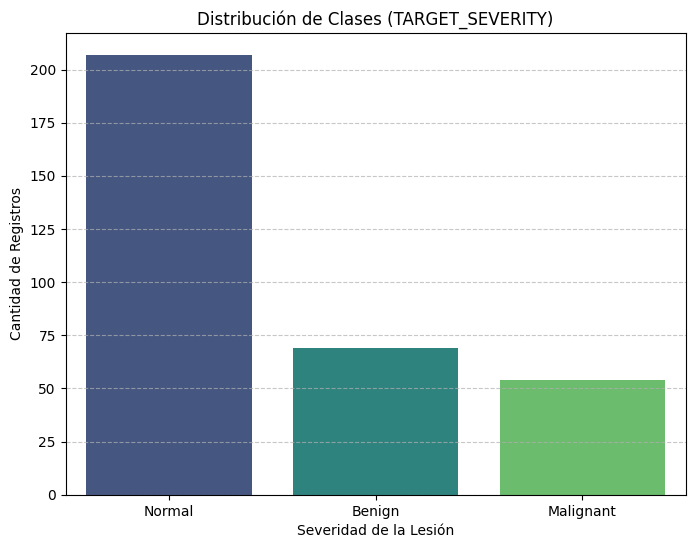


Cantidad de casos Benignos: 69
Cantidad de casos Malignos: 54
Cantidad de casos Normales: 207

Se detecta un desbalance de clases significativo. Se considerará el uso de `class_weight='balanced'` o técnicas de oversampling/undersampling más adelante.


In [ ]:
print("--- Análisis de la distribución de clases ---")
class_distribution = df_combined['TARGET_SEVERITY'].value_counts()
print(class_distribution)

# Calcular porcentajes
class_percentage = df_combined['TARGET_SEVERITY'].value_counts(normalize=True) * 100
print("\nPorcentaje de cada clase:\n", class_percentage)

# Visualización de la distribución de clases
plt.figure(figsize=(8, 6))
sns.barplot(x=class_distribution.index, y=class_distribution.values, palette='viridis')
plt.title('Distribución de Clases (TARGET_SEVERITY)')
plt.xlabel('Severidad de la Lesión')
plt.ylabel('Cantidad de Registros')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Conteo de casos benignos, malignos y normales
benign_count = class_distribution.get('Benign', 0)
malignant_count = class_distribution.get('Malignant', 0)
normal_count = class_distribution.get('Normal', 0)

print(f"\nCantidad de casos Benignos: {benign_count}")
print(f"Cantidad de casos Malignos: {malignant_count}")
print(f"Cantidad de casos Normales: {normal_count}")

# Evaluación de desbalance de clases
if malignant_count > 0 and (benign_count / malignant_count > 2 or normal_count / malignant_count > 2):
    print("\nSe detecta un desbalance de clases significativo. Se considerará el uso de `class_weight='balanced'` o técnicas de oversampling/undersampling más adelante.")
else:
    print("\nEl desbalance de clases no parece ser crítico, pero se mantendrá en observación.")

### 3.3 Procesamiento de Imágenes y Extracción de Características (GLCM, estadísticas)

## 9. Procesamiento de imágenes

### Estrategia de procesamiento de imágenes y extracción de características

Dado que `RandomForestClassifier` trabaja mejor con datos tabulares numéricos, no alimentaremos directamente los píxeles crudos de las imágenes. En su lugar, extraeremos características relevantes. La estrategia para este prototipo académico será:

1.  **Redimensionamiento (Resizing):** Todas las imágenes se redimensionarán a un tamaño común y más pequeño (por ejemplo, 128x128 píxeles). Esto reduce la dimensionalidad y el tiempo de procesamiento, manteniendo suficiente detalle para la extracción de características de textura y estadísticas.
2.  **Conversión a escala de grises y Normalización de Píxeles:** Las mamografías son típicamente imágenes en escala de grises. Los valores de píxeles se normalizarán entre 0 y 1 para estandarizar el rango de entrada para los algoritmos.
3.  **Extracción de Características de Imagen (Globales):**
    *   **Características Estadísticas:** Se calcularán el valor medio, la desviación estándar, el mínimo, el máximo y la mediana de la intensidad de píxeles de toda la imagen. Estas características capturan propiedades generales de brillo y contraste.
    *   **Características de Textura GLCM (Gray-Level Co-occurrence Matrix):** Se utilizarán propiedades como contraste, energía y homogeneidad de la GLCM. Estas características son muy efectivas para describir la textura de la imagen, que es crucial en mamografías para identificar patrones anómalos. Se calcularán para un offset de 1 píxel y un ángulo de 0 grados.
4.  **Características de Metadatos:**
    *   Las coordenadas `X`, `Y` y el `RADIUS` de la lesión (ya imputados con 0 cuando no hay lesión) se utilizarán directamente como características numéricas.
    *   Se creará una característica binaria `has_lesion` (1 si `X`, `Y`, `RADIUS` no son 0, 0 en caso contrario) para indicar explícitamente la presencia de coordenadas de lesión.
    *   La variable `BG` (tejido mamario: 'D', 'F', 'G') se convertirá a un formato numérico mediante codificación One-Hot.

Esta combinación busca capturar tanto la información clínica proporcionada en los metadatos como las características visuales clave de las mamografías, manteniendo la complejidad manejable para un prototipo. Aunque la información de la región de interés (ROI) es valiosa, para simplificar el prototipo inicial, nos centraremos en características globales de la imagen y metadatos, y reservaremos la extracción de características específicas de ROI para una futura mejora.

In [ ]:
from skimage.feature import graycomatrix, graycoprops

IMAGE_SIZE = (128, 128) # Tamaño de redimensionamiento para las imágenes

def preprocess_image(image_path, size=IMAGE_SIZE):
    try:
        img = Image.open(image_path).convert('L')  # Convertir a escala de grises ('L')
        img = img.resize(size) # Redimensionar la imagen
        img_array = np.array(img) # Convertir a numpy array
        img_array = img_array / 255.0 # Normalizar píxeles a [0, 1]
        return img_array
    except Exception as e:
        print(f"Error al procesar la imagen {image_path}: {e}")
        return None

def extract_image_features(img_array):
    if img_array is None:
        return np.full(10, np.nan) # Retorna NaN si hay error en la imagen

    features = []

    # Características estadísticas globales
    features.append(np.mean(img_array))
    features.append(np.std(img_array))
    features.append(np.min(img_array))
    features.append(np.max(img_array))
    features.append(np.median(img_array))

    # Convertir a enteros para GLCM (skimage espera int)
    img_256 = (img_array * 255).astype(np.uint8)

    # Características de textura GLCM (Gray-Level Co-occurrence Matrix)
    # Consideramos un GLCM simple: distancia 1, ángulo 0
    try:
        glcm = graycomatrix(img_256, [1], [0], levels=256, symmetric=True, normed=True)
        features.append(graycoprops(glcm, 'contrast')[0, 0])
        features.append(graycoprops(glcm, 'energy')[0, 0])
        features.append(graycoprops(glcm, 'homogeneity')[0, 0])
        features.append(graycoprops(glcm, 'correlation')[0, 0])
        features.append(graycoprops(glcm, 'dissimilarity')[0, 0])
    except ValueError as ve:
        # Esto puede ocurrir si la imagen es constante o tiene un rango de valores muy pequeño
        print(f"Advertencia: Error al calcular GLCM para una imagen: {ve}")
        features.extend(np.full(5, np.nan)) # Añadir NaNs para GLCM features

    return np.array(features)

print("Aplicando procesamiento de imágenes y extracción de características...")

# Aplicar preprocesamiento y extracción de características a todas las imágenes
# Esto puede tomar un tiempo considerable
image_features_list = []
for idx, row in df_combined.iterrows(): # df_combined se asume definido por la celda anterior f8796cf1
    img_array = preprocess_image(row['image_path'])
    features = extract_image_features(img_array)
    image_features_list.append(features)

df_image_features = pd.DataFrame(image_features_list, columns=[
    'img_mean', 'img_std', 'img_min', 'img_max', 'img_median',
    'glcm_contrast', 'glcm_energy', 'glcm_homogeneity', 'glcm_correlation', 'glcm_dissimilarity'
])

# Unir las características de imagen al DataFrame combinado para formar df_processed
df_processed = pd.concat([df_combined.reset_index(drop=True), df_image_features], axis=1)

# --- INICIO DE LA LIMPIEZA Y TRANSFORMACIÓN DE df_processed ---

# 1. Imputación de NaNs en X, Y, RADIUS con 0 (si no se realizó antes)
# NaNs en X, Y, RADIUS significan ausencia de lesión en esas coordenadas.
print("Imputando NaNs en X, Y, RADIUS con 0...")
df_processed['X'].fillna(0, inplace=True)
df_processed['Y'].fillna(0, inplace=True)
df_processed['RADIUS'].fillna(0, inplace=True)
print("Valores faltantes en X, Y, RADIUS después de imputación:")
print(df_processed[['X', 'Y', 'RADIUS']].isnull().sum())

# 2. Creación de la característica binaria 'has_lesion'
df_processed['has_lesion'] = ((df_processed['X'] != 0) | (df_processed['Y'] != 0) | (df_processed['RADIUS'] != 0)).astype(int)

# 3. Codificación One-Hot para la columna 'BG'
# Verificar si 'BG' aún existe en df_processed antes de codificar
if 'BG' in df_processed.columns:
    df_processed = pd.get_dummies(df_processed, columns=['BG'], prefix='BG', drop_first=False) # Mantener todas las columnas dummy para BG
    print("Columnas BG codificadas: ", [col for col in df_processed.columns if col.startswith('BG_')])

# Convertir columnas booleanas (generadas por get_dummies) a enteros 0 o 1
# Esto asegura que todas las características sean numéricas antes de la selección de X
for col in ['BG_D', 'BG_F', 'BG_G']:
    if col in df_processed.columns and df_processed[col].dtype == bool:
        df_processed[col] = df_processed[col].astype(int)
        print(f"  Columna '{col}' convertida de bool a int.")

# 4. Eliminar columnas que no se utilizarán como características en el modelo (identificadores, ya procesadas, etc.)
columns_to_drop_from_df_processed = [
    'REFNUM', 'REFNUM_normalized', 'CLASS', 'SEVERITY', 'image_path'
]

# Asegurarse de no eliminar 'TARGET_SEVERITY' que es la variable objetivo
existing_cols_to_drop = [col for col in columns_to_drop_from_df_processed if col in df_processed.columns]
if existing_cols_to_drop:
    df_processed.drop(columns=existing_cols_to_drop, inplace=True)
    print(f"Columnas eliminadas de df_processed: {', '.join(existing_cols_to_drop)}")

# 5. Manejo de NaNs restantes en características de imagen (por si hubo errores durante la extracción)
print("Imputando NaNs restantes en características de imagen...")
for col in df_image_features.columns:
    if df_processed[col].isnull().any():
        df_processed[col].fillna(df_processed[col].mean(), inplace=True)
        print(f"  Imputando NaNs en {col} con la media.")

# --- FIN DE LA LIMPIEZA Y TRANSFORMACIÓN DE df_processed ---

print("\n--- Primeras 5 filas del DataFrame con características de imagen y metadatos (limpio) ---")
print(df_processed.head())

print("\n--- Información del DataFrame final de características (limpio) ---")
print(df_processed.info())

print("\nValores faltantes finales en df_processed (deberían ser cero excepto TARGET_SEVERITY antes de la división):")
print(df_processed.isnull().sum()[df_processed.isnull().sum() > 0])

Aplicando procesamiento de imágenes y extracción de características...
Imputando NaNs en X, Y, RADIUS con 0...
Valores faltantes en X, Y, RADIUS después de imputación:
X         0
Y         0
RADIUS    0
dtype: int64
Columnas BG codificadas:  ['BG_D', 'BG_F', 'BG_G']
  Columna 'BG_D' convertida de bool a int.
  Columna 'BG_F' convertida de bool a int.
  Columna 'BG_G' convertida de bool a int.
Columnas eliminadas de df_processed: REFNUM, REFNUM_normalized, CLASS, SEVERITY, image_path
Imputando NaNs restantes en características de imagen...

--- Primeras 5 filas del DataFrame con características de imagen y metadatos (limpio) ---
       X      Y  RADIUS TARGET_SEVERITY  img_mean   img_std  img_min  \
0  535.0  425.0   197.0          Benign  0.165423  0.286252      0.0   
1  522.0  280.0    69.0          Benign  0.204767  0.301286      0.0   
2    0.0    0.0     0.0          Normal  0.214860  0.329090      0.0   
3    0.0    0.0     0.0          Normal  0.245000  0.338515      0.0   
4  

### 3.4 Limpieza y Transformación de Metadatos (Imputación X, Y, Radius; One-Hot Encoding BG)